In [1]:
%pip install numpy matplotlib nbconvert scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono   # a stopwatch

GRAVITY = 9.81   # m/s^2

Note: you may need to restart the kernel to use updated packages.


# Ballistic Tracking with Kalman Filters

A radar measures the **position** of a projectile at regular intervals, with noise. From these positions alone, the filter must recover the full state: position, velocity and acceleration.

The notebook starts with a linear filter on one axis and ends with a nonlinear filter in three dimensions, with gravity and air drag.

| Step | What is added |
|---|---|
| 1 | One axis, constant acceleration, linear Kalman filter |
| 2 | Many runs of the same filter |
| 3 | Three independent axes |
| 4 | Air drag couples the axes: the Extended Kalman Filter (EKF) |
| 5 | A mortar shell: mass and drag |
| 6 | A second kind of measurement: Doppler velocity |
| 7 | Estimating the drag coefficient during the flight |
| 8 | The Unscented Kalman Filter (UKF) against the EKF |
| 9 | A sensor slower than the filter |

Every model here takes two noise arguments. Both are standard deviations:

- `measurement_uncertainty` is the standard deviation $\sigma_\text{meas}$ of the position-sensor noise, in m.
- `process_uncertainty`, written $q$, is the strength of the random accelerations that the model leaves out, such as gusts. They make the velocity wander: after a time $t$ it has moved by a random amount of standard deviation $q\sqrt{t}$. So $q$ is in m/s$^{3/2}$, and it is the velocity wander, in m/s, built up over one second.

## The State-Space Model

A Kalman filter estimates a hidden **state** $\mathbf x$ from noisy **measurements** $\mathbf z$. At every sample it does two things:

- **predict**: advance the state by one time step with the equations of motion;
- **update**: correct the prediction with the new measurement.

For a linear system and a time step $\Delta t = 1/f_s$, where $f_s$ is the sample rate:

$$\mathbf x_{k+1} = F\,\mathbf x_k + (\text{process noise}),\qquad \mathbf z_k = H\,\mathbf x_k + (\text{measurement noise})$$

| Symbol | Meaning |
|---|---|
| $\mathbf x$ | state: the quantities we track |
| $P$ | state covariance: the filter's uncertainty about $\mathbf x$ |
| $F$ | transition matrix: moves the state one step forward |
| $H$ | measurement matrix: what the sensor reads from the state |
| $Q$ | process-noise covariance: how far the real motion strays from $F$ in one step |
| $R$ | measurement-noise covariance |

This notebook uses two models.

**One axis, constant acceleration.** The state is $\mathbf x = (p,\,v,\,a)$: position, velocity and acceleration, with $\dot p = v$, $\dot v = a$ and $\dot a = 0$. The sensor reads $p$, so $H = (1\;0\;0)$ and $R = \sigma_\text{meas}^2$.

**Three axes with drag.** Each axis has its own $(p, v, a)$, and the velocity vector obeys

$$\dot{\mathbf v} = \mathbf g - \frac{c_d}{m}\,\lVert\mathbf v\rVert\,\mathbf v$$

which is gravity plus air drag, for a drag coefficient $c_d$ and a mass $m$. The drag term is not linear in the state, so there is no fixed matrix $F$. The **Extended Kalman Filter** (EKF) replaces it at each step by the linear model that fits best near the current estimate (Step 4).

## Step 1 — One Axis, Linear Kalman Filter

A body is thrown straight up at 128 m/s. A sensor reads its altitude 128 times per second, with a noise of 10 m. The filter also estimates the velocity and the acceleration, which are never measured.

For constant acceleration, one time step $\Delta t$ gives

$$F = \begin{pmatrix} 1 & \Delta t & \tfrac{1}{2}\Delta t^2 \\ 0 & 1 & \Delta t \\ 0 & 0 & 1 \end{pmatrix},\qquad
H = \begin{pmatrix} 1 & 0 & 0 \end{pmatrix}$$

The process noise enters through the velocity:

$$Q = q^2\begin{pmatrix} \Delta t^3/3 & \Delta t^2/2 & 0 \\ \Delta t^2/2 & \Delta t & 0 \\ 0 & 0 & 0 \end{pmatrix}$$

The entry $q^2\Delta t$ is the velocity variance added in one step. The other entries follow from it, because a velocity error also moves the position. With $q = 1$ m/s$^{3/2}$, the velocity wanders by about 5 m/s over the 26 s of flight.

The two noise values set a balance. A large $\sigma_\text{meas}$ makes the filter rely on the model: the estimate is smooth but slow to react. A large $q$ makes it rely on the measurements: the estimate reacts quickly but is noisier.

In [2]:
from kalman.apps.ballistics import BallisticLinearModel

FLIGHT = 28   # s: a little more than the 26 s the body spends in the air

bulletbill = BallisticLinearModel("Z", sample_rate=128,
                                  measurement_uncertainty=10,    # σ_meas [m]
                                  process_uncertainty=1.0,       # q [m/s^1.5]
                                  random_seed=42)
bulletbill.initial_state([0, 128, -GRAVITY])   # altitude [m], velocity [m/s], acceleration [m/s²]
bulletbill.print()

chrono.restart()
sample = bulletbill.sample(FLIGHT)                                # the true path and its noisy measurements
chrono.lap("Sampling completed")
record = bulletbill.filter(sample.zk, smooth=False, reset=True)   # forward filter only
chrono.lap("Filtering completed")
chrono.summary()

BallisticLinearModel(KalmanModel) @ fs=128Hz
    Ballistic State Model (v1.3)
        Linear constant-acceleration toy model; position
        measured.
    Dimensions Summary:
        State Vector....................................: 3 dims (BallisticState<POSITION, SPEED, ACCELERATION>)
        Observation.....................................: 1 dim  (BallisticObservable<POSITION>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 3x1 dims
        State Covariance (P0)...........................: 3x3 dims

Chrono summary:
    #   label                         t          ΔT
  ───   ───────────────────   ─────────   ─────────
    1.  Sampling completed      50.3 ms     50.3 ms
    2.  Filtering completed     72.2 ms     21.9 ms
  ───   ───────────────────   ─────────   ─────────
        total                   72.2 ms


### What Process Noise Does

Without process noise the body would follow the **ideal** parabola. The **true** path is one random draw: the random accelerations push it off the parabola, further and further as time passes.

The grey band shows where such paths can fall: the ideal path ± 3 standard deviations of the accumulated wander. It is obtained by repeating the filter's own predict step for the covariance, $P \leftarrow F P F^\top + Q$, starting from zero.

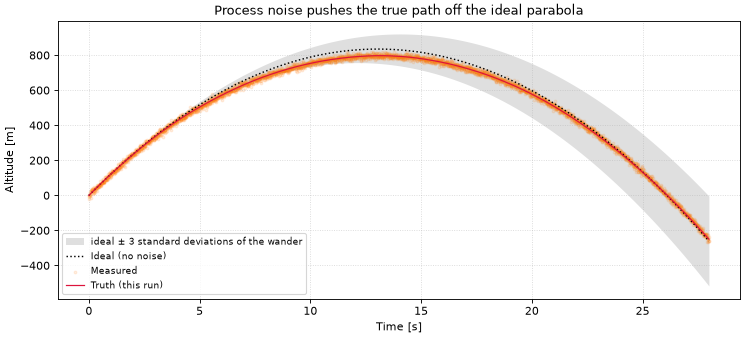

apex: ideal 835 m, this run 797 m;  largest |truth − ideal| = 39 m


In [3]:
# Spread of the true paths around the ideal one: propagate P from 0 with the model's F and Q.
F = np.asarray(bulletbill.F(np.zeros((bulletbill.n, 1))))
Q = np.asarray(bulletbill.Q(0))
P = np.zeros((bulletbill.n, bulletbill.n))
env = np.empty(len(sample.time))
for k in range(len(env)):
    env[k] = np.sqrt(max(P[0, 0], 0.0))      # standard deviation of the position at step k
    P = F @ P @ F.T + Q

t     = sample.time
ideal = np.asarray(bulletbill.ideal(duration=FLIGHT))[:, 0]
truth = np.asarray(sample.xk)[:, 0]
meas  = np.asarray(sample.zk)[:, 0]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(t, ideal - 3*env, ideal + 3*env, color="gray", alpha=0.25, lw=0,
                label="ideal ± 3 standard deviations of the wander")
ax.plot(t, ideal, ":", color="black", lw=1.3, label="Ideal (no noise)")
ax.scatter(t, meas, s=6, alpha=0.12, color="tab:orange", label="Measured")
ax.plot(t, truth, "-", color="crimson", lw=1.1, label="Truth (this run)")
ax.set_title("Process noise pushes the true path off the ideal parabola")
ax.set_xlabel("Time [s]"); ax.set_ylabel("Altitude [m]")
ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.5); plt.show()

print(f"apex: ideal {ideal.max():.0f} m, this run {truth.max():.0f} m;  "
      f"largest |truth − ideal| = {np.abs(truth - ideal).max():.0f} m")

### The Filter's Estimate

The dashboard below has one time slider for four panels: position, speed, acceleration, and a histogram of the measurement errors. The shaded band is the filter's own uncertainty, ± 3 standard deviations taken from $P$.

In [4]:
bulletbill.plot(record, sample=sample, interactive=True, sigma=3)

What to notice:

- **Position**: the estimate follows the truth much more closely than the scatter of the measurements.
- **Speed**: never measured, but recovered from how the position changes.
- **Acceleration**: the hardest of the three to see in position data. Its estimate drifts within about 1 m/s² of −9.81 m/s², and its band narrows only slowly.
- **Histogram**: the measurement errors are centred on zero, with a width close to $\sigma_\text{meas}$ = 10 m.

Try doubling `measurement_uncertainty` to 20 m: the bands widen and the estimate reacts more slowly.

### Is the Filter Consistent?

A filter is **consistent** when its errors are as large as the uncertainty it reports. `diagnostics` draws the four checks introduced in `00_Kalman101.ipynb`:

- the **innovation** $\nu$, the measurement minus the predicted measurement, which should scatter around zero inside its ± 3 standard deviation band;
- the **Kalman gain** $K$, which settles to a steady value;
- the **Normalized Innovation Squared (NIS)**, whose average should be close to the measurement dimension $m = 1$;
- the **Normalized Estimation Error Squared (NEES)**, whose average should be close to the state dimension $n = 3$. It needs the true state, so it exists only in simulation.

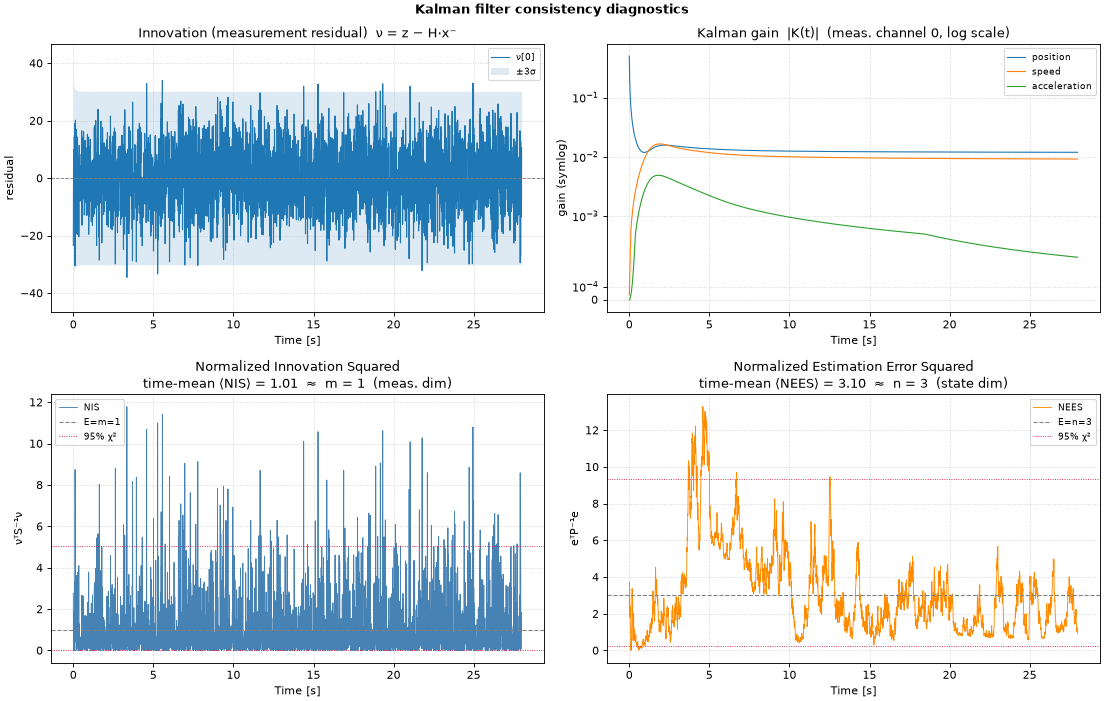

Normalized Innovation Squared,        mean = 1.01   (ideal ≈ m = 1)
Normalized Estimation Error Squared,  mean = 3.10   (ideal ≈ n = 3)


In [5]:
bulletbill.diagnostics(sample=sample)
plt.show()

print(f"Normalized Innovation Squared,        mean = {bulletbill.nis().mean():.2f}   (ideal ≈ m = {bulletbill.m})")
print(f"Normalized Estimation Error Squared,  mean = {bulletbill.nees(sample.xk).mean():.2f}   (ideal ≈ n = {bulletbill.n})")

### Apex and Impact Time

Two numbers summarize a shot: the **apex** (the greatest altitude) and the **impact time** (when the body is back at altitude 0).

Both follow from one state $(p, v, a)$ by continuing the motion at constant acceleration. The velocity vanishes after a time $-v/a$, at altitude $p - v^2/(2a)$; the impact time is the later root of $p + v\,t + \tfrac12 a\,t^2 = 0$. Given the covariance of the state, `apex` and `impact_time` also return the uncertainty of their result.

We apply them to the smoothed track. The **smoother** is a second pass, backward in time, that lets each estimate also use the later measurements. The apex is read from the highest sample, the impact from the last sample above ground.

In [6]:
smoothed = bulletbill.smooth()
x_smooth = np.asarray(smoothed.xk); P_smooth = np.asarray(smoothed.Pk); t_smooth = np.asarray(smoothed.time)
p_true = np.asarray(sample.xk)[:, 0]

# Apex, from the sample of greatest estimated altitude
apex_idx = int(np.argmax(x_smooth[:, 0]))
apex     = bulletbill.apex(x_smooth[apex_idx], P_smooth[apex_idx])
print(f"Apex   : {apex.height:6.1f} ± {apex.height_std:.1f} m   "
      f"at t = {t_smooth[apex_idx] + apex.time:5.2f} s     "
      f"(truth {p_true.max():.1f} m at {t_smooth[int(np.argmax(p_true))]:.2f} s)")

# Impact, from the last sample before the estimate goes below ground
impact_idx       = np.where(np.diff(np.sign(x_smooth[:, 0])) < 0)[0][0]
impact           = bulletbill.impact_time(x_smooth[impact_idx], P_smooth[impact_idx], level=0.0)
true_impact_idx  = np.where(np.diff(np.sign(p_true)) < 0)[0][0]
true_impact_time = (t_smooth[true_impact_idx]
                     - p_true[true_impact_idx] * (t_smooth[true_impact_idx + 1] - t_smooth[true_impact_idx])
                       / (p_true[true_impact_idx + 1] - p_true[true_impact_idx]))
print(f"Impact : t = {t_smooth[impact_idx] + impact.time:6.3f} ± {impact.time_std:.3f} s   "
      f"at {impact.speed:.0f} m/s   (truth t = {true_impact_time:.3f} s)")

Apex   :  796.9 ± 0.5 m   at t = 13.11 s     (truth 797.5 m at 13.11 s)
Impact : t = 26.118 ± 0.004 s   at -124 m/s   (truth t = 26.116 s)


## Step 2 — Many Runs

One run shows one random draw of the noise, which may be lucky or unlucky. Repeating the experiment with fresh noise, a **Monte Carlo** study, shows how the filter behaves in general.

`KalmanRecordCollection` holds the runs and plots them together. Each run has its own true path, so the curves fan out with time: that spread is the process noise of Step 1, not a filter error.

The filter error is checked separately. If the filter is consistent, its position error should fall inside its own ± 2 standard deviation band about 95 % of the time.

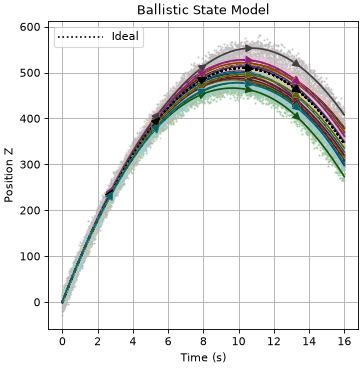

20 runs: position error inside the filter's ± 2 standard deviations 92 % of the time


In [7]:
from kalman.framework.io.collection import KalmanRecordCollection

bulletbill = BallisticLinearModel("Z", sample_rate=128,
                                  measurement_uncertainty=10,    # σ_meas [m]
                                  process_uncertainty=1.0,       # q [m/s^1.5]
                                  random_seed=1)
bulletbill.initial_state([0, 100, -GRAVITY])

N = 20
samples, records = [], []
for i in range(N):
    samples.append(bulletbill.sample(16))                                    # a new draw each time
    records.append(bulletbill.filter(samples[-1], smooth=True, reset=True))

collection = KalmanRecordCollection(records)
collection.plot(samples=samples, component=bulletbill.states.POSITION)
plt.show()

error = np.array([np.asarray(r.xk)[:, 0] - np.asarray(s.xk)[:, 0] for r, s in zip(records, samples)])
sigma = np.sqrt(np.asarray(records[0].Pk)[:, 0, 0])      # the same for every run
print(f"{N} runs: position error inside the filter's ± 2 standard deviations "
      f"{100*np.mean(np.abs(error) < 2*sigma):.0f} % of the time")

The fraction is close to 95 %, so the uncertainty the filter reports can be trusted. A much lower value would mean an over-confident filter, typically because $Q$ or $R$ is set too small.

## Step 3 — Three Independent Axes

Motion happens in three dimensions. As long as no force links the axes, a 3D tracker is three copies of the 1D filter, one each for X, Y and Z.

`CompositeKalmanModel` stacks the three models into one. The state has nine numbers, $(p_x, v_x, a_x,\; p_y, v_y, a_y,\; p_z, v_z, a_z)$, and $F$, $H$, $Q$, $R$ are made of three separate blocks, so no information passes from one axis to another. Gravity acts on Z only, as the constant acceleration $-g$.

In [8]:
from kalman.framework.models.composite import CompositeKalmanModel

axis = dict(sample_rate=128,
            measurement_uncertainty=10,    # σ_meas [m]
            process_uncertainty=0.2)       # q [m/s^1.5]
bulletbill = CompositeKalmanModel(
    BallisticLinearModel("X", random_seed=42, **axis),
    BallisticLinearModel("Y", random_seed=43, **axis),
    BallisticLinearModel("Z", random_seed=44, **axis),
)
bulletbill.initial_state([
    [100, 100,        0],    # X: [position, velocity, acceleration]
    [200, 100,        0],    # Y
    [300, 100, -GRAVITY],    # Z
])

sample = bulletbill.sample(16)
record = bulletbill.filter(sample.zk, smooth=False, reset=True)

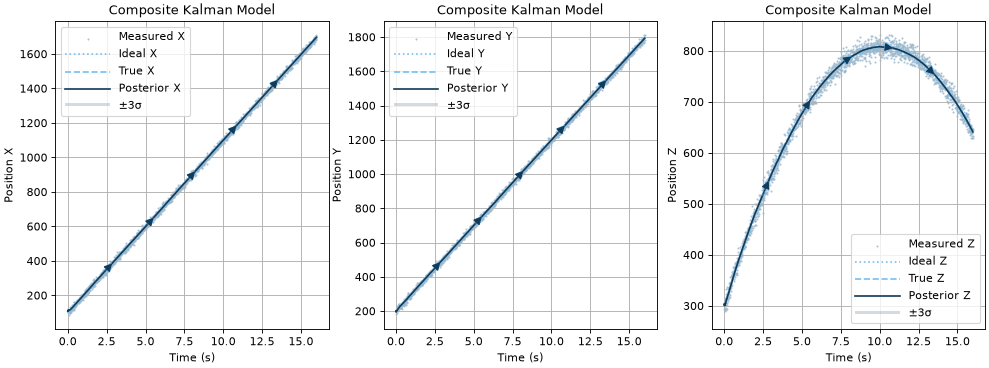

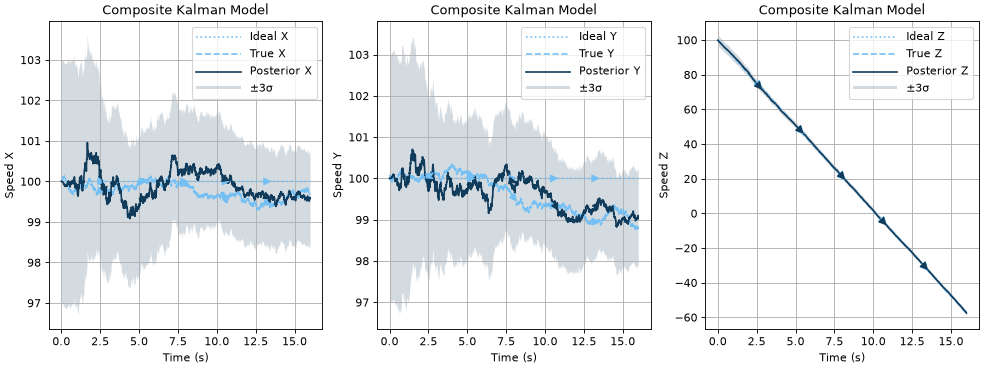

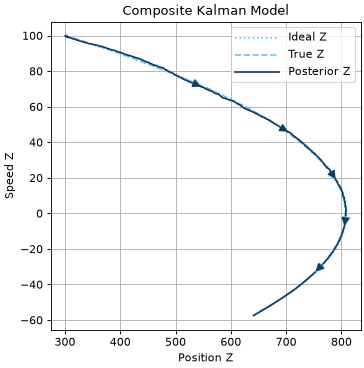

In [9]:
from kalman.helpers import get_canvas

# dim selects the axis: 0 for X, 1 for Y, 2 for Z. sigma=3 shades ± 3 standard deviations.
canvas = get_canvas(3, 1)
for dim in range(3):
    record.plot(sample=sample, component="position", dim=dim, fig=canvas[dim], sigma=3)

canvas = get_canvas(3, 1)
for dim in range(3):
    record.plot(sample=sample, component="speed", dim=dim, fig=canvas[dim], sigma=3)

# Altitude against vertical speed
record.plot(sample=sample, component=["position", "speed"], dim=[2, 2])
plt.show()

What to notice:

- The X and Y speeds stay near 100 m/s and wander by about 1 m/s: this is the process noise, followed by the filter inside its ± 3 standard deviation band.
- The Z speed falls steadily under gravity, from +100 m/s through zero at the apex.
- The last plot shows altitude against vertical speed: the speed is zero where the altitude is greatest.

## Step 4 — Three Axes With Drag: the Extended Kalman Filter

Air drag slows the projectile along its direction of motion, with a strength that grows as the square of the speed:

$$\mathbf a_\text{drag} = -\frac{c_d}{m}\,\lVert\mathbf v\rVert\,\mathbf v$$

The speed $\lVert\mathbf v\rVert$ contains all three velocity components, so the axes are no longer independent and the motion is no longer a matrix times the state.

The **Extended Kalman Filter** (EKF) deals with this in two parts. It predicts the state with the full nonlinear motion function $f$. For the covariance it needs a matrix, so it uses the **Jacobian** $F = \partial f/\partial\mathbf x$: the matrix of partial derivatives, which describes $f$ near the current estimate. Here the Jacobian is computed numerically.

The state is the same nine numbers as in Step 3 and the sensor reads the three positions. The mass and the drag coefficient are those of the mortar shell of Step 5.

BallisticModel(KalmanModel) @ fs=64Hz
    Ballistic Extended Model (v1.0)
        Nonlinear 3D ballistic model with gravity, drag,
        and thrust.
    Dimensions Summary:
        State Vector....................................: 9 dims (BallisticState<POSITION, SPEED, ACCELERATION>)
        Observation.....................................: 3 dims (BallisticObservable<POSITION>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 9x1 dims
        State Covariance (P0)...........................: 9x9 dims
    Metadata Entries:
        G      = 6.674e-11 (float)
        M      = 5.972e+24 (float)
        c_drag = 0.0006 (float)
        g      = 9.81 (float)
        m      = 4.2 (float)



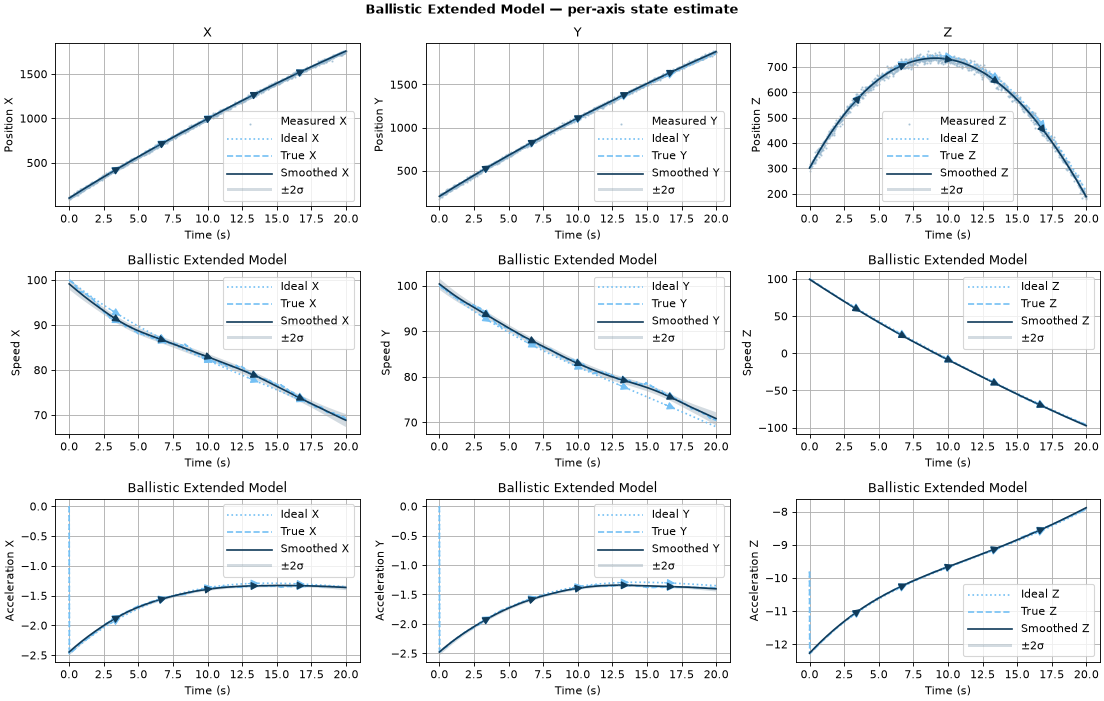

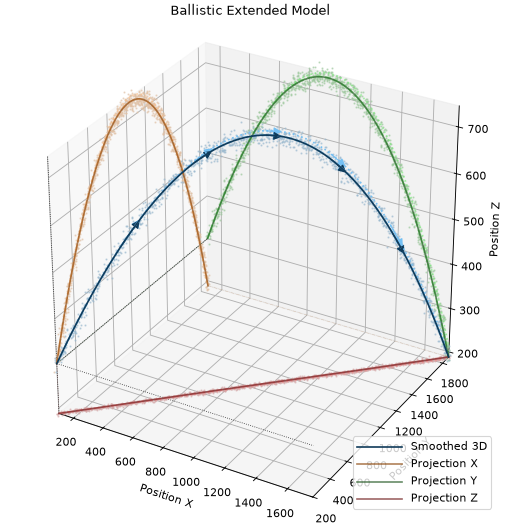

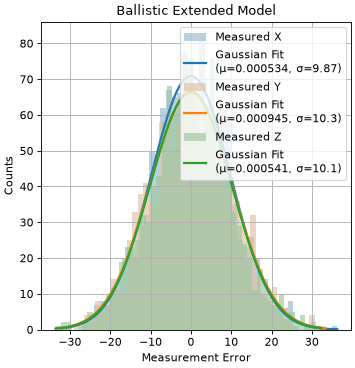

In [10]:
from kalman.apps.ballistics import BallisticModel

MASS   = 4.2      # shell mass [kg]
C_DRAG = 6.0e-4   # drag coefficient c_d [kg/m]

bulletbill = BallisticModel("XYZ", order=3, fs=64,
                            m=MASS, c_drag=C_DRAG,
                            measurement_uncertainty=10,    # σ_meas [m]
                            process_uncertainty=0.5,       # q [m/s^1.5]
                            random_seed=42)

# One row per axis: [position, velocity, acceleration]
bulletbill.initial_state([
    [100, 100,        0],    # X
    [200, 100,        0],    # Y
    [300, 100, -GRAVITY],    # Z
])
bulletbill.print()

sample = bulletbill.sample(20)
record = bulletbill.filter(sample.zk, smooth=True, reset=True)

# Position, speed and acceleration for each axis, with the ± 2 standard deviation band
bulletbill.plot(record, sample=sample, sigma=2)

# The trajectory in 3D, and the histogram of the measurement errors
record.plot(sample=sample, component="position", view="3d")
record.plot_error(sample=sample)
plt.show()

What to notice:

- The X and Y speeds now fall, from 100 m/s to about 70 m/s. The constant-acceleration model of Step 3 has no force along X and Y and cannot produce this.
- The accelerations are no longer constant. They are largest at launch, where the projectile is fastest, and the vertical one differs from $-g$ by the drag.

## Step 5 — A Mortar Shell: Mass and Drag

$$\dot{\mathbf v}=\mathbf g-\frac{c_d}{m}\,\lVert\mathbf v\rVert\,\mathbf v$$

Gravity accelerates every body alike. Drag is a force, so the acceleration it causes is divided by the mass: a heavier shell of the same shape slows less and flies farther. The drag coefficient is $c_d = \tfrac12\rho\,C_D A$, with $\rho$ the air density, $A$ the frontal area and $C_D$ a number that depends on the shape.

Drag appears in the filter twice. Its known average is part of $f$. What we do not know about it, because $c_d$ is uncertain and the wind and air density vary, belongs in the process noise. Here we assume the drag is known to ± 15 % and take 15 % of the drag deceleration at the muzzle as $q$. Using a deceleration as $q$ amounts to assuming that the error is redrawn about once per second.

The cell tracks an 81 mm mortar shell (4.2 kg, muzzle velocity 250 m/s, elevation 60°) with a radar noise of 10 m. It then repeats the flight with the same shell at three masses, to show the effect of mass alone.

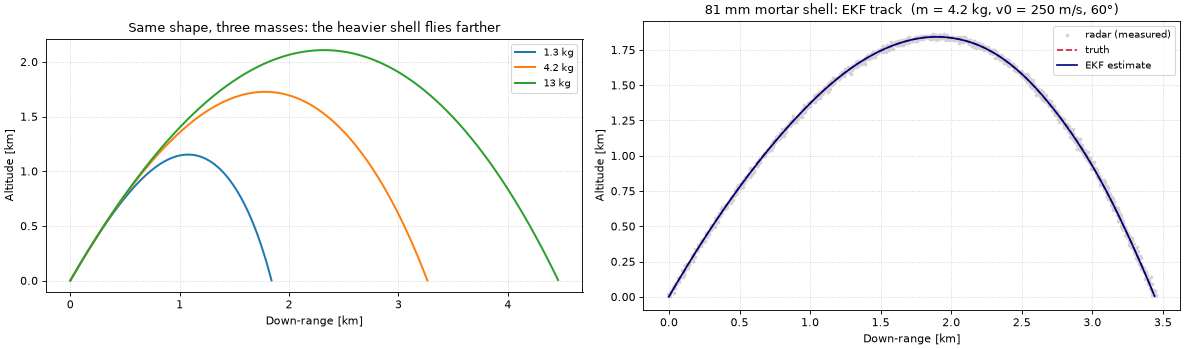

process noise from the drag uncertainty: q = 1.34 m/s^1.5
   1.3 kg:  range =  1.84 km   apex =  1.15 km
   4.2 kg:  range =  3.26 km   apex =  1.73 km
    13 kg:  range =  4.46 km   apex =  2.11 km
EKF position error (RMS), 4.2 kg shell = 1.2 m


In [11]:
V0     = 250.0           # muzzle velocity [m/s]
ELEV   = np.radians(60)  # launch elevation
FS     = 32              # radar rate [Hz]
# MASS = 4.2 kg and C_DRAG = 6.0e-4 kg/m come from Step 4.

# Fire in the X–Z plane: X is down-range, Z is up.
def mortar_init(v0, elev):
    return [[0.0, v0*np.cos(elev),  0.0],        # X
            [0.0, 0.0,              0.0],        # Y
            [0.0, v0*np.sin(elev), -GRAVITY]]    # Z

def impact_range(x, z):                      # X where the shell comes back to z = 0
    below = np.where(z < 0)[0]
    if len(below) == 0 or below[0] == 0: return x[-1]
    k = below[0]; z0, z1 = z[k-1], z[k]
    return x[k-1] + (x[k]-x[k-1]) * (z0/(z0-z1))

T_FLIGHT = 1.05 * 2.0*V0*np.sin(ELEV)/GRAVITY   # flight time without drag, plus 5 % [s]

# Process noise from the drag uncertainty: 15 % of the drag deceleration at the muzzle.
EPS_DRAG = 0.15
Q_DRAG   = EPS_DRAG * (C_DRAG/MASS) * V0**2     # used as q [m/s^1.5]

# Track the 4.2 kg shell with the EKF
mortar = BallisticModel("XYZ", order=3, fs=FS,
                        m=MASS, c_drag=C_DRAG, g=GRAVITY,
                        measurement_uncertainty=10,   # σ_meas [m]
                        process_uncertainty=Q_DRAG,   # q [m/s^1.5]
                        random_seed=7)
mortar.initial_state(mortar_init(V0, ELEV))
sample = mortar.sample(T_FLIGHT)
record = mortar.filter(sample.zk, smooth=True, reset=True)

# Same shape, same launch, three masses, no noise
sweep = {}
for mass in (1.3, 4.2, 13.0):
    shot = BallisticModel("XYZ", order=3, fs=FS, m=mass, c_drag=C_DRAG, g=GRAVITY,
                          process_uncertainty=0.0, measurement_uncertainty=1.0, random_seed=0)
    shot.initial_state(mortar_init(V0, ELEV))
    traj = shot.sample(T_FLIGHT)
    sweep[f"{mass:g} kg"] = (traj.xk[:, 0], traj.xk[:, 6])     # (down-range, altitude)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

for lbl, (x, z) in sweep.items():             # left: the three masses, down to the ground
    k = z >= 0
    ax[0].plot(x[k]/1000, z[k]/1000, lw=1.8, label=lbl)
ax[0].set_title("Same shape, three masses: the heavier shell flies farther")
ax[0].set_xlabel("Down-range [km]"); ax[0].set_ylabel("Altitude [km]")
ax[0].legend(fontsize=9); ax[0].grid(True, ls=":", alpha=0.6); ax[0].set_aspect("equal", "box")

mk = sample.xk[:, 6] >= 0                      # right: the EKF track of the 4.2 kg shell
ax[1].scatter(sample.zk[mk, 0]/1000, sample.zk[mk, 2]/1000, s=5, color="lightgray", zorder=0, label="radar (measured)")
ax[1].plot(sample.xk[mk, 0]/1000, sample.xk[mk, 6]/1000, '--', color="crimson", lw=1.5, label="truth")
ax[1].plot(record.xk[mk, 0]/1000, record.xk[mk, 6]/1000, '-',  color="navy",    lw=1.5, label="EKF estimate")
ax[1].set_title(f"81 mm mortar shell: EKF track  (m = {MASS} kg, v0 = {V0:.0f} m/s, 60°)")
ax[1].set_xlabel("Down-range [km]"); ax[1].set_ylabel("Altitude [km]")
ax[1].legend(fontsize=9); ax[1].grid(True, ls=":", alpha=0.6); ax[1].set_aspect("equal", "box")

plt.tight_layout(); plt.show()

print(f"process noise from the drag uncertainty: q = {Q_DRAG:.2f} m/s^1.5")
for lbl, (x, z) in sweep.items():
    print(f"  {lbl:>7s}:  range = {impact_range(x, z)/1000:5.2f} km   apex = {z.max()/1000:5.2f} km")
print(f"EKF position error (RMS), 4.2 kg shell = {np.sqrt(np.mean((record.xk[:,[0,6]]-sample.xk[:,[0,6]])**2)):.1f} m")

### Process Noise That Follows the Speed

Drag grows as the square of the speed, and so does a ± 15 % error on it. With `drag_uncertainty=ε` the filter uses a process noise that follows the speed: large just after launch, small near the apex where the shell is slow.

The plot compares the velocity uncertainty of this filter with that of a filter using a constant $q$ = 0.3 m/s$^{3/2}$, on the radar track of the cell above.

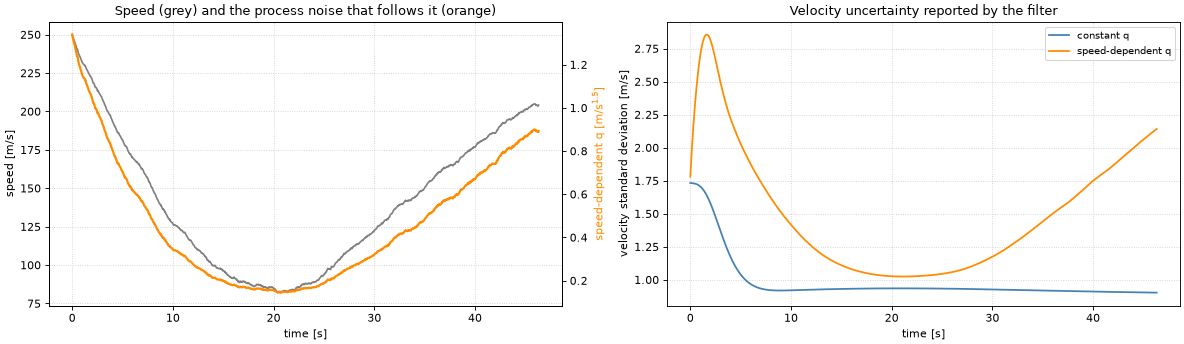

speed-dependent q: 1.34 m/s^1.5 at launch, 0.14 m/s^1.5 at its lowest
velocity std, first 50 samples:  constant q = 1.71 m/s   speed-dependent = 2.48 m/s
velocity std, mid-flight      :  constant q = 0.93 m/s   speed-dependent = 1.03 m/s


In [12]:
ekf_const = BallisticModel("XYZ", order=3, fs=FS, m=MASS, c_drag=C_DRAG, g=GRAVITY,
                           measurement_uncertainty=10, process_uncertainty=0.3)
ekf_drag  = BallisticModel("XYZ", order=3, fs=FS, m=MASS, c_drag=C_DRAG, g=GRAVITY,
                           measurement_uncertainty=10, process_uncertainty=0.3,
                           drag_uncertainty=EPS_DRAG)        # adds ε·(c_d/m)·|v|² to q
ekf_const.initial_state(mortar_init(V0, ELEV)); rec_const = ekf_const.filter(sample.zk, smooth=False, reset=True)
ekf_drag .initial_state(mortar_init(V0, ELEV)); rec_drag  = ekf_drag .filter(sample.zk, smooth=False, reset=True)

t      = sample.time
speed  = np.linalg.norm(sample.xk[:, [1, 4, 7]], axis=1)                 # true speed
q_drag = EPS_DRAG * (C_DRAG/MASS) * speed**2                             # the speed-dependent part of q
velocity_sigma = lambda rec: np.sqrt(np.clip(rec.Pk[:, [1, 4, 7], [1, 4, 7]].sum(1), 0.0, None))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

ax[0].plot(t, speed, color="gray", lw=1.5)
ax[0].set_xlabel("time [s]"); ax[0].set_ylabel("speed [m/s]"); ax[0].grid(True, ls=":", alpha=0.6)
ax0b = ax[0].twinx()
ax0b.plot(t, q_drag, color="darkorange", lw=2.0)
ax0b.set_ylabel("speed-dependent q [m/s$^{1.5}$]", color="darkorange")
ax[0].set_title("Speed (grey) and the process noise that follows it (orange)")

ax[1].plot(t, velocity_sigma(rec_const), color="steelblue",  lw=1.6, label="constant q")
ax[1].plot(t, velocity_sigma(rec_drag),  color="darkorange", lw=1.6, label="speed-dependent q")
ax[1].set_title("Velocity uncertainty reported by the filter")
ax[1].set_xlabel("time [s]"); ax[1].set_ylabel("velocity standard deviation [m/s]")
ax[1].legend(fontsize=9); ax[1].grid(True, ls=":", alpha=0.6)

plt.tight_layout(); plt.show()

mid = slice(len(t)//2 - 25, len(t)//2 + 25)
print(f"speed-dependent q: {q_drag.max():.2f} m/s^1.5 at launch, {q_drag.min():.2f} m/s^1.5 at its lowest")
print(f"velocity std, first 50 samples:  constant q = {velocity_sigma(rec_const)[:50].mean():.2f} m/s   speed-dependent = {velocity_sigma(rec_drag)[:50].mean():.2f} m/s")
print(f"velocity std, mid-flight      :  constant q = {velocity_sigma(rec_const)[mid].mean():.2f} m/s   speed-dependent = {velocity_sigma(rec_drag)[mid].mean():.2f} m/s")

## Step 6 — A Second Kind of Measurement: Doppler Velocity

From positions alone, the filter has to deduce the velocity from how the position changes. A Doppler radar adds a direct velocity measurement: the **radial velocity**, the part of the velocity along the line from the radar to the projectile. With the radar at the origin,

$$v_r = \mathbf v\cdot\frac{\mathbf p}{\lVert\mathbf p\rVert}$$

The measurement becomes $\mathbf z = (p_x,\,p_y,\,p_z,\,v_r)$. Since $v_r$ mixes position and velocity nonlinearly, the EKF treats the measurement function $h$ as it treats $f$: it uses the Jacobian $H = \partial h/\partial\mathbf x$. Combining different kinds of sensors in one filter is called **sensor fusion**.

The two filters below see the same flight, with a noise of 10 m on the position and 1 m/s on the radial velocity. The first one ignores the Doppler channel.

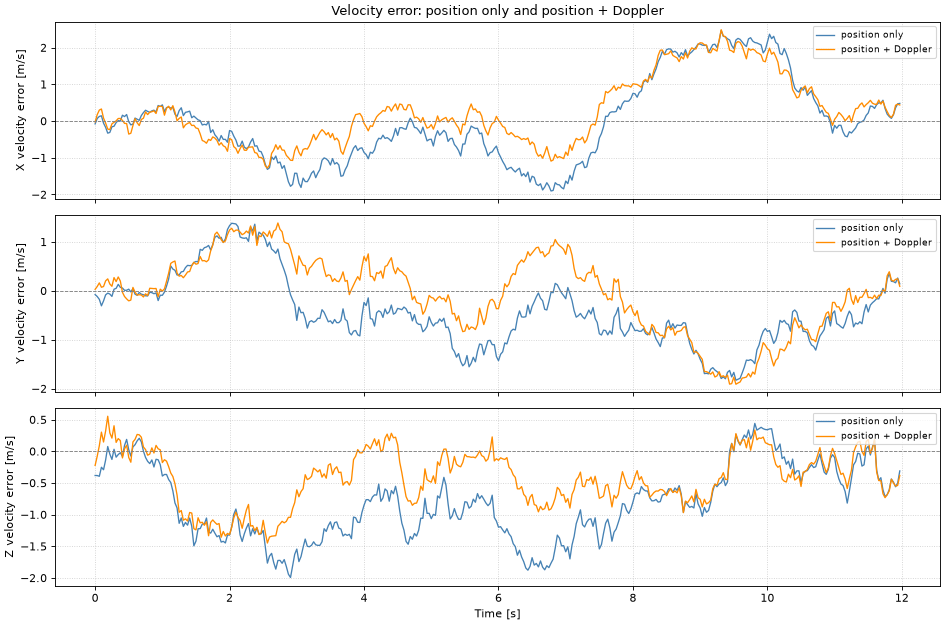

X velocity error (RMS):  position only  1.14 m/s   position + Doppler  0.93 m/s
Y velocity error (RMS):  position only  0.84 m/s   position + Doppler  0.79 m/s
Z velocity error (RMS):  position only  1.00 m/s   position + Doppler  0.61 m/s


In [13]:
class BallisticDopplerModel(BallisticModel):
    # Measures [px, py, pz, v_r], with v_r the velocity along the line of sight from the origin.

    def __init__(self, *args, vel_noise=1.0, **kwargs):
        super().__init__(*args, **kwargs)

        # R grows from 3×3 to 4×4: the new entry is the Doppler noise variance
        R = np.zeros((4, 4), dtype=self.dtype)
        R[:3, :3] = self._R
        R[3, 3]   = float(vel_noise) ** 2
        self._R = R
        self.m  = 4

        dtype = self.dtype
        def doppler_h(x, v=None, t=None):
            x = np.asarray(x, dtype=dtype).reshape(-1)
            p   = x[[0, 3, 6]]
            vel = x[[1, 4, 7]]
            r   = float(np.linalg.norm(p))
            line_of_sight = p / r if r > 1.0 else np.array([0., 0., 1.], dtype=dtype)
            z = np.zeros((4, 1), dtype=dtype)
            z[:3, 0] = p
            z[3,  0] = float(vel @ line_of_sight)
            if v is not None:
                z += np.asarray(v, dtype=dtype).reshape(4, 1)
            return z
        self.h = doppler_h


INIT = [[100, 100, 0], [200, 100, 0], [300, 100, -GRAVITY]]   # the launch of Step 4
FS, T = 32, 12
common = dict(order=3, fs=FS, m=MASS, c_drag=C_DRAG,
              measurement_uncertainty=10,    # σ_meas [m]
              process_uncertainty=0.5)       # q [m/s^1.5]

# Position + Doppler: this model also generates the flight and its four measurements
ekf_dop = BallisticDopplerModel("XYZ", vel_noise=1.0, random_seed=7, **common)   # Doppler noise 1 m/s
ekf_dop.initial_state(INIT)
sample  = ekf_dop.sample(T)
rec_dop = ekf_dop.filter(sample.zk, smooth=False, reset=True)

# Position only: the same flight, without the fourth column
ekf_pos = BallisticModel("XYZ", **common)
ekf_pos.initial_state(INIT)
rec_pos = ekf_pos.filter(sample.zk[:, :3], smooth=False, reset=True)

t = sample.time
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].set_title("Velocity error: position only and position + Doppler")
for ax, dim, lbl in zip(axes, [1, 4, 7], ["X", "Y", "Z"]):
    ax.plot(t, rec_pos.xk[:, dim] - sample.xk[:, dim], color='steelblue',  lw=1.2, label='position only')
    ax.plot(t, rec_dop.xk[:, dim] - sample.xk[:, dim], color='darkorange', lw=1.2, label='position + Doppler')
    ax.axhline(0, color='gray', lw=0.8, ls='--')
    ax.set_ylabel(f"{lbl} velocity error [m/s]")
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, linestyle=':', alpha=0.6)
axes[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()

for lbl, dim in [("X", 1), ("Y", 4), ("Z", 7)]:
    rms_p = np.sqrt(np.mean((rec_pos.xk[:, dim] - sample.xk[:, dim])**2))
    rms_d = np.sqrt(np.mean((rec_dop.xk[:, dim] - sample.xk[:, dim])**2))
    print(f"{lbl} velocity error (RMS):  position only {rms_p:5.2f} m/s   position + Doppler {rms_d:5.2f} m/s")

The Doppler channel lowers the velocity error on all three axes. The gain is moderate, because 32 position fixes per second already constrain the velocity to about 1 m/s.

## Step 7 — Estimating the Drag Coefficient During the Flight

So far the drag coefficient was known. Often it is not, and a filter with the wrong drag predicts a wrong trajectory at every step.

The remedy is **state augmentation**: append $c_d$ to the state as a tenth component and let the filter estimate it along with the motion. Its model is a constant with a very small random drift, which keeps the filter able to adjust it.

This works because drag leaves a trace in the measurements. The shell slows down more than gravity alone explains, and the filter attributes the difference to $c_d$.

Three models are compared on one flight:

1. the truth, flown with $c_d$ = 6·10⁻⁴ kg/m;
2. a filter that assumes no drag;
3. the augmented filter, which starts from $c_d$ = 0 with an initial standard deviation of 10⁻³ kg/m.

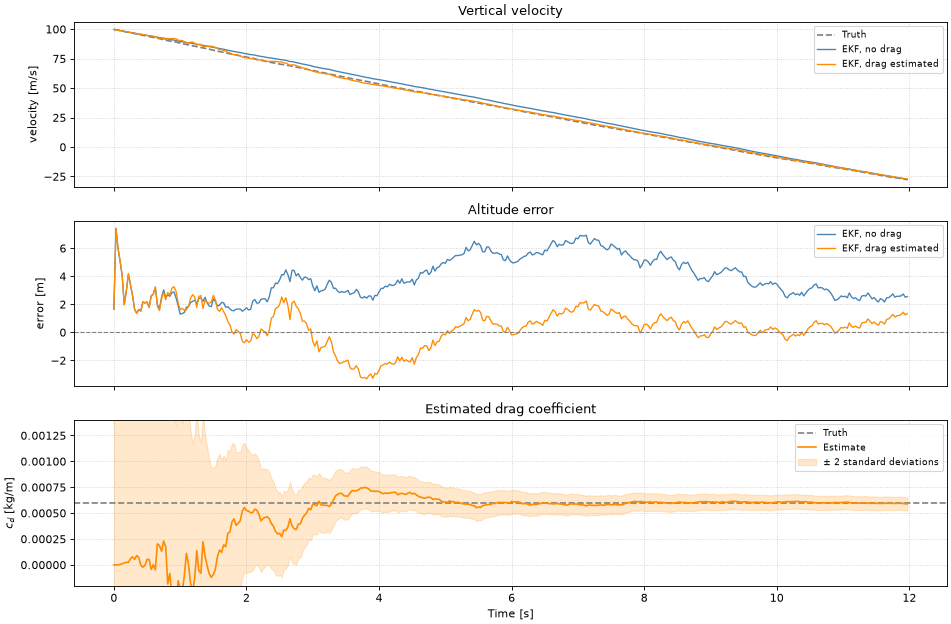

altitude error (RMS):           no drag 4.1 m     drag estimated 1.5 m
vertical velocity error (RMS):  no drag 2.9 m/s   drag estimated 0.9 m/s
drag coefficient at the end: 5.90e-04 ± 3.2e-05 kg/m   (truth 6.0e-04 kg/m)


In [14]:
class BallisticAugmentedModel(BallisticModel):
    # State of 10 numbers: the 9 of BallisticModel, plus c_drag as the last one.

    def __init__(self, name, *, drag_process_noise=1e-6, drag_initial_uncertainty=1e-3, **kwargs):
        kwargs['c_drag'] = 0.0   # the value used at each step is the tenth state
        super().__init__(name, **kwargs)
        self.n = 10

        # Q, x0 and P0 each get one more entry for c_drag
        Q = np.zeros((10, 10), dtype=self.dtype)
        Q[:9, :9] = self._Q
        Q[9,  9]  = float(drag_process_noise) ** 2          # drift of c_drag per step (variance)
        self._Q = Q

        x0 = np.zeros((10, 1), dtype=self.dtype)
        x0[:9] = self.x0                                    # c_drag starts at 0
        self.x0 = x0

        P0 = np.zeros((10, 10), dtype=self.dtype)
        P0[:9, :9] = self.P0
        P0[9,  9]  = float(drag_initial_uncertainty) ** 2   # how unsure we are of c_drag at the start
        self.P0 = P0

        parent_f = BallisticModel.f.__get__(self, type(self))
        parent_h = BallisticModel.h.__get__(self, type(self))
        model, dtype = self, self.dtype

        def augmented_f(x, u=None, w=None, t=None):
            x = np.asarray(x, dtype=dtype).reshape(-1, 1)
            model["c_drag"] = float(x[9, 0])                # move the 9 motion states with the current c_drag
            x9 = parent_f(x[:9], u=u, w=None, t=t)
            model["c_drag"] = 0.0
            xn = np.zeros((10, 1), dtype=dtype)
            xn[:9] = np.asarray(x9, dtype=dtype).reshape(9, 1)
            xn[9, 0] = float(x[9, 0])                       # c_drag itself stays as it is
            if w is not None:
                xn += np.asarray(w, dtype=dtype).reshape(10, 1)
            return xn

        def augmented_h(x, v=None, t=None):
            x = np.asarray(x, dtype=dtype).reshape(-1, 1)
            return parent_h(x[:9], v=v, t=t)                # the sensor still reads the three positions

        self.f = augmented_f
        self.h = augmented_h

    def initial_state(self, x0=None, P0=None):
        # Accept the 9 motion states and append c_drag = 0
        if x0 is not None and getattr(self, 'n', 9) == 10:
            flat = np.asarray(x0, dtype=getattr(self, 'dtype', np.float64)).ravel()
            if flat.size == 9:
                x10 = np.zeros((10, 1), dtype=flat.dtype)
                x10[:9, 0] = flat
                x0 = x10
        super().initial_state(x0=x0, P0=P0)


FS, T = 32, 12
common = dict(order=3, fs=FS, m=MASS,
              measurement_uncertainty=10,    # σ_meas [m]
              process_uncertainty=0.3)       # q [m/s^1.5]

# 1. The truth, with drag
truth_model = BallisticModel("XYZ", c_drag=C_DRAG, random_seed=42, **common)
truth_model.initial_state(INIT)
truth_sample = truth_model.sample(T)

# 2. A filter that assumes no drag
ekf_nodrag = BallisticModel("XYZ", c_drag=0.0, **common)
ekf_nodrag.initial_state(INIT)
rec_nodrag = ekf_nodrag.filter(truth_sample.zk, smooth=False, reset=True)

# 3. The augmented filter, which estimates the drag
ekf_aug = BallisticAugmentedModel("XYZ",
                                  drag_process_noise=1e-6,          # drift per step [kg/m]
                                  drag_initial_uncertainty=1e-3,    # initial standard deviation [kg/m]
                                  **common)
ekf_aug.initial_state(INIT)
rec_aug = ekf_aug.filter(truth_sample.zk, smooth=False, reset=True)

t = truth_sample.time
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].set_title("Vertical velocity")
axes[0].plot(t, truth_sample.xk[:, 7], '--', color='gray',       lw=1.5, label='Truth')
axes[0].plot(t, rec_nodrag.xk[:, 7],   '-',  color='steelblue',  lw=1.2, label='EKF, no drag')
axes[0].plot(t, rec_aug.xk[:, 7],      '-',  color='darkorange', lw=1.2, label='EKF, drag estimated')
axes[0].set_ylabel("velocity [m/s]"); axes[0].legend(fontsize=8); axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].set_title("Altitude error")
axes[1].plot(t, rec_nodrag.xk[:, 6] - truth_sample.xk[:, 6], '-', color='steelblue',  lw=1.2, label='EKF, no drag')
axes[1].plot(t, rec_aug.xk[:, 6]    - truth_sample.xk[:, 6], '-', color='darkorange', lw=1.2, label='EKF, drag estimated')
axes[1].axhline(0, color='gray', lw=1, linestyle='--')
axes[1].set_ylabel("error [m]"); axes[1].legend(fontsize=8); axes[1].grid(True, linestyle=':', alpha=0.6)

c_sigma = np.sqrt(rec_aug.Pk[:, 9, 9])
axes[2].set_title("Estimated drag coefficient")
axes[2].axhline(C_DRAG, color='gray', lw=1.5, linestyle='--', label='Truth')
axes[2].plot(t, rec_aug.xk[:, 9], '-', color='darkorange', lw=1.5, label='Estimate')
axes[2].fill_between(t, rec_aug.xk[:, 9] - 2*c_sigma, rec_aug.xk[:, 9] + 2*c_sigma, color='darkorange', alpha=0.2,
                     label='± 2 standard deviations')
axes[2].set_ylim(-2e-4, 1.4e-3)
axes[2].set_ylabel("$c_d$ [kg/m]"); axes[2].set_xlabel("Time [s]")
axes[2].legend(fontsize=8); axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

rms = lambda rec, dim: np.sqrt(np.mean((rec.xk[:, dim] - truth_sample.xk[:, dim])**2))
print(f"altitude error (RMS):           no drag {rms(rec_nodrag, 6):.1f} m     drag estimated {rms(rec_aug, 6):.1f} m")
print(f"vertical velocity error (RMS):  no drag {rms(rec_nodrag, 7):.1f} m/s   drag estimated {rms(rec_aug, 7):.1f} m/s")
print(f"drag coefficient at the end: {rec_aug.xk[-1, 9]:.2e} ± {c_sigma[-1]:.1e} kg/m   (truth {C_DRAG:.1e} kg/m)")

The augmented filter finds the drag coefficient within a few seconds and tracks the shell with a smaller error. The filter without drag keeps predicting too fast a shell; the measurements pull it back at every step, but it always lags behind.

## Step 8 — The UKF Against the EKF

The EKF linearizes $f$ with a Jacobian. The **Unscented Kalman Filter** (UKF) needs no Jacobian. It places a small set of points around the current estimate, the **sigma points**, sends each of them through the exact $f$, and recomputes the mean and the covariance from where they land. This follows a curved $f$ better than a linearization does, at the price of $2n+1$ evaluations of $f$ per step for a state of $n$ numbers.

Only the filter changes: `UnscentedKalmanFilter(model)` takes the same `BallisticModel`.

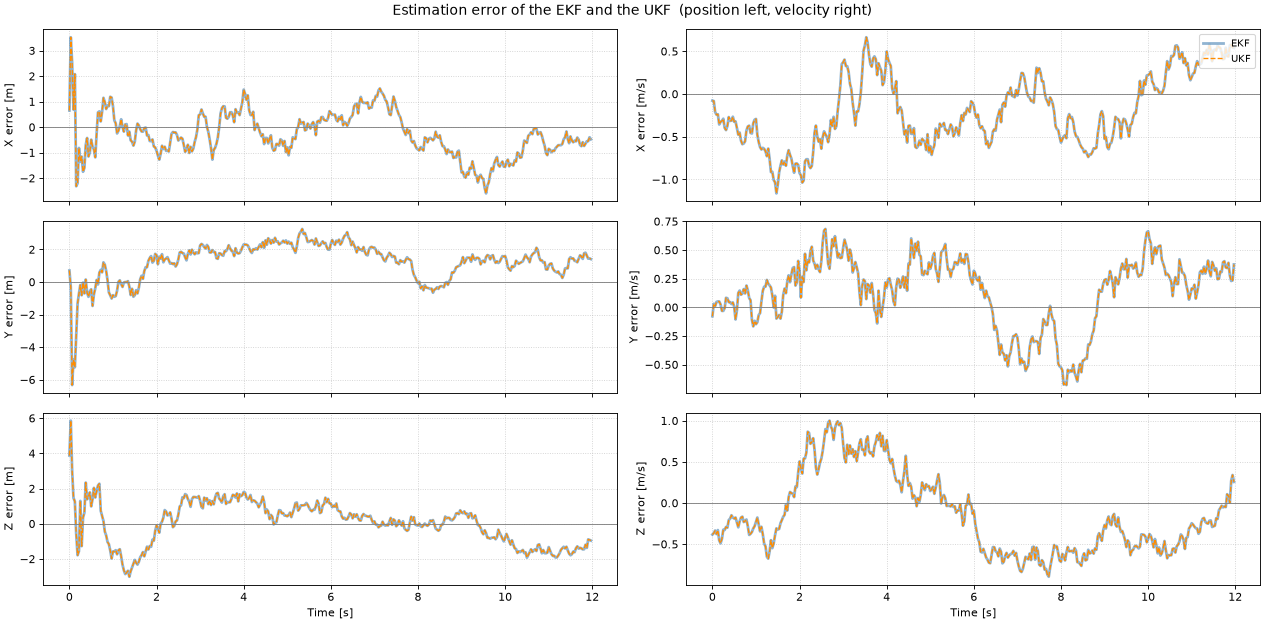

error (RMS)           EKF          UKF
Position X        0.912 m      0.912 m
Position Y        1.706 m      1.706 m
Position Z        1.220 m      1.220 m
Velocity X        0.459 m/s    0.459 m/s
Velocity Y        0.335 m/s    0.335 m/s
Velocity Z        0.505 m/s    0.505 m/s

largest difference between the two position estimates: 0.4 mm


In [15]:
from kalman.framework.filters.ukf import UnscentedKalmanFilter

FS, T = 32, 12
common = dict(order=3, fs=FS, m=MASS, c_drag=C_DRAG,
              measurement_uncertainty=10,    # σ_meas [m]
              process_uncertainty=0.3)       # q [m/s^1.5]

truth_cmp = BallisticModel("XYZ", random_seed=99, **common)
truth_cmp.initial_state(INIT)
sample_cmp = truth_cmp.sample(T)

# EKF
ekf_cmp = BallisticModel("XYZ", **common)
ekf_cmp.initial_state(INIT)
rec_ekf = ekf_cmp.filter(sample_cmp.zk, smooth=False, reset=True)

# UKF on the same model
ukf_model = BallisticModel("XYZ", **common)
ukf_model.initial_state(INIT)
ukf = UnscentedKalmanFilter(ukf_model, alpha=1e-3, beta=2.0, kappa=0.0)   # the usual sigma-point spread settings
rec_ukf = ukf.filter(sample_cmp.zk, reset=True)

t_cmp   = sample_cmp.time
names   = ["X", "Y", "Z"]
idx_pos = [0, 3, 6]
idx_vel = [1, 4, 7]

fig, axes = plt.subplots(3, 2, figsize=(16, 8), sharex=True)
fig.suptitle("Estimation error of the EKF and the UKF  (position left, velocity right)", fontsize=13)
for row, (lbl, pos_dim, vel_dim) in enumerate(zip(names, idx_pos, idx_vel)):
    for col, (dim, unit) in enumerate([(pos_dim, "m"), (vel_dim, "m/s")]):
        ax = axes[row, col]
        truth = sample_cmp.xk[:, dim]
        ax.plot(t_cmp, rec_ekf.xk[:, dim] - truth, '-',  color='steelblue',  lw=2.5, alpha=0.6, label='EKF')
        ax.plot(t_cmp, rec_ukf.xk[:, dim] - truth, '--', color='darkorange', lw=1.2, label='UKF')
        ax.axhline(0, color='gray', lw=0.8)
        ax.set_ylabel(f"{lbl} error [{unit}]")
        ax.grid(True, linestyle=':', alpha=0.6)
        if row == 0 and col == 1:
            ax.legend(loc='upper right', fontsize=9)
axes[-1, 0].set_xlabel("Time [s]")
axes[-1, 1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()

print(f"{'error (RMS)':<14} {'EKF':>10} {'UKF':>12}")
for name, indices, unit in [("Position", idx_pos, "m"), ("Velocity", idx_vel, "m/s")]:
    for i, dim in enumerate(indices):
        truth = sample_cmp.xk[:, dim]
        rms_e = np.sqrt(np.mean((rec_ekf.xk[:, dim] - truth) ** 2))
        rms_u = np.sqrt(np.mean((rec_ukf.xk[:, dim] - truth) ** 2))
        print(f"{name} {names[i]:<5} {rms_e:>8.3f} {unit:<3} {rms_u:>8.3f} {unit}")

print(f"\nlargest difference between the two position estimates: "
      f"{1000*np.abs(rec_ekf.xk[:, idx_pos] - rec_ukf.xk[:, idx_pos]).max():.1f} mm")

The two filters give the same result. Over one step of 1/32 s the drag bends the motion very little, so the EKF's linear approximation is already accurate and the UKF has nothing to add. The UKF pays off when $f$ or $h$ curve strongly over the range of the filter's uncertainty.

## Step 9 — A Sensor Slower Than the Filter

A GPS receiver delivers a fix 10 times per second, while we may want an estimate 128 times per second. The filter then runs at 128 Hz: at a step with a fix it predicts and updates; at a step without one it only predicts, and its uncertainty grows until the next fix.

A missing measurement is written as a row of `NaN` in the measurement array. `make_multirate_input` builds that array from the fixes and their rate.

Three filters run on the same flight, with a GPS noise of 5 m:

| Filter | Predicts at | Updates at |
|---|---|---|
| Reference | 128 Hz | 128 Hz, as if a fix came at every step, which no such receiver provides |
| 10 Hz only | 10 Hz | 10 Hz |
| Multi-rate | 128 Hz | 10 Hz |

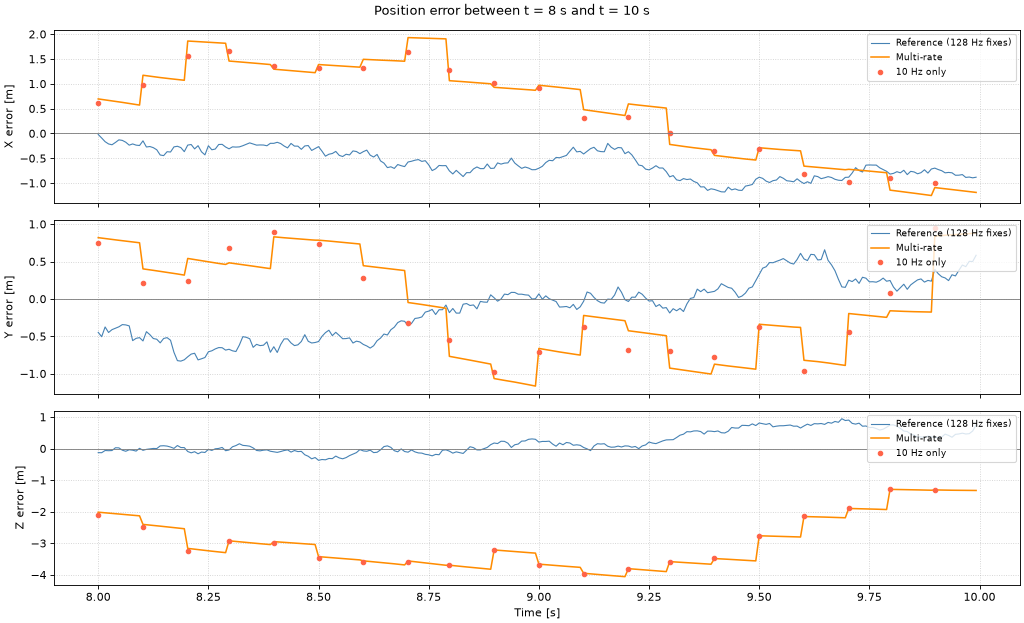

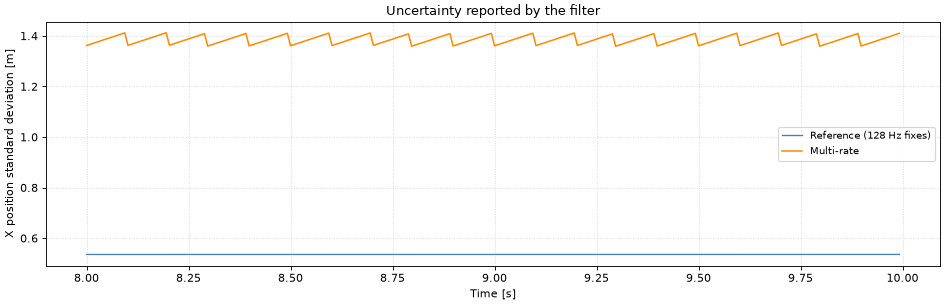

error (RMS)   reference   10 Hz only   multi-rate
Position X       0.48 m       1.25 m       1.18 m
Position Y       0.57 m       1.93 m       1.97 m
Position Z       0.66 m       1.77 m       1.57 m
Velocity X       0.47 m/s     0.78 m/s     0.81 m/s
Velocity Y       0.68 m/s     0.95 m/s     1.02 m/s
Velocity Z       0.78 m/s     1.24 m/s     1.04 m/s


In [16]:
from kalman.helpers import make_multirate_input

FS_BASE = 128.0   # rate of the filter [Hz]
FS_GPS  = 10.0    # rate of the GPS fixes [Hz]
T       = 16.0    # duration [s]
common  = dict(order=3, m=MASS, c_drag=C_DRAG,
               measurement_uncertainty=5,     # σ_meas [m]
               process_uncertainty=0.5)       # q [m/s^1.5]

model = BallisticModel("XYZ", fs=FS_BASE, random_seed=17, **common)
model.initial_state(INIT)
sample = model.sample(T)
N_base = len(sample.zk)

# Reference: a fix at every 128 Hz step
rec_full = model.filter(sample.zk, smooth=False, reset=True)

# 10 Hz only: keep one fix every 0.1 s and run a 10 Hz filter on them
n_gps   = int(T * FS_GPS)
gps_idx = np.clip(np.round(np.arange(n_gps) * FS_BASE / FS_GPS).astype(int), 0, N_base - 1)
z_gps   = sample.zk[gps_idx]
t_gps   = sample.time[gps_idx]
model_10 = BallisticModel("XYZ", fs=FS_GPS, **common)
model_10.initial_state(INIT)
rec_gps = model_10.filter(z_gps, smooth=False, reset=True)

# Multi-rate: the same fixes on the 128 Hz grid, NaN everywhere else
z_multirate = make_multirate_input([(z_gps, FS_GPS)], base_fs=FS_BASE)
assert len(z_multirate) == N_base
rec_mr = model.filter(z_multirate, smooth=False, reset=True)

t_full  = sample.time
names   = ["X", "Y", "Z"]
idx_pos = [0, 3, 6]
idx_vel = [1, 4, 7]

# Estimation error over two seconds, to see what happens between fixes
zoom = (t_full >= 8) & (t_full < 10)
zoom_gps = (t_gps >= 8) & (t_gps < 10)
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
fig.suptitle("Position error between t = 8 s and t = 10 s", fontsize=12)
for ax, dim, lbl in zip(axes, idx_pos, names):
    truth = sample.xk[:, dim]
    ax.plot(t_full[zoom], (rec_full.xk[:, dim] - truth)[zoom], '-', color='steelblue',  lw=1.0, label='Reference (128 Hz fixes)')
    ax.plot(t_full[zoom], (rec_mr.xk[:, dim] - truth)[zoom],   '-', color='darkorange', lw=1.4, label='Multi-rate')
    ax.plot(t_gps[zoom_gps], (rec_gps.xk[:, dim] - truth[gps_idx])[zoom_gps], 'o', color='tomato', ms=4, label='10 Hz only')
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_ylabel(f"{lbl} error [m]")
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, linestyle=':', alpha=0.6)
axes[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()

# Position uncertainty of the filter: it grows between fixes and drops at each one
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t_full[zoom], np.sqrt(rec_full.Pk[zoom, 0, 0]), '-', color='steelblue',  lw=1.2, label='Reference (128 Hz fixes)')
ax.plot(t_full[zoom], np.sqrt(rec_mr.Pk[zoom, 0, 0]),   '-', color='darkorange', lw=1.4, label='Multi-rate')
ax.set_xlabel("Time [s]"); ax.set_ylabel("X position standard deviation [m]")
ax.set_title("Uncertainty reported by the filter")
ax.legend(fontsize=9); ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout(); plt.show()

# The 10 Hz estimate is joined by straight lines to compare it at every 128 Hz step
print(f"{'error (RMS)':<12} {'reference':>10} {'10 Hz only':>12} {'multi-rate':>12}")
for name, indices, unit in [("Position", idx_pos, "m"), ("Velocity", idx_vel, "m/s")]:
    for i, dim in enumerate(indices):
        truth  = sample.xk[:, dim]
        rms_f  = np.sqrt(np.mean((rec_full.xk[:, dim] - truth)**2))
        rms_mr = np.sqrt(np.mean((rec_mr.xk[:, dim]   - truth)**2))
        rms_g  = np.sqrt(np.mean((np.interp(t_full, t_gps, rec_gps.xk[:, dim]) - truth)**2))
        print(f"{name} {names[i]:<3} {rms_f:>8.2f} {unit:<3} {rms_g:>8.2f} {unit:<3} {rms_mr:>8.2f} {unit}")

What to notice:

- The reference is the most accurate. It receives about 13 times more fixes than the other two.
- The multi-rate filter and the 10 Hz filter use the same fixes and are about equally accurate. What the multi-rate filter adds is an estimate at every 128 Hz step, obtained from the equations of motion rather than by joining the 10 Hz estimates with straight lines.
- The uncertainty of the multi-rate filter is a sawtooth: it grows while the filter only predicts and drops at each fix.